In [ ]:
import pandas as pd

columns = [
    "classe", "cap_shape", "cap_surface", "cap_color", "bruises", "odor",
    "gill_attachment", "gill_spacing", "gill_size", "gill_color",
    "stalk_shape", "stalk_root", "stalk_surface_above_ring",
    "stalk_surface_below_ring", "stalk_color_above_ring",
    "stalk_color_below_ring", "veil_type", "veil_color", "ring_number",
    "ring_type", "spore_print_color", "population", "habitat",
]

df = pd.read_csv("agaricus-lepiota.data", header=None, names=columns)
df.head()

,classe,cap_shape,cap_surface,cap_color,bruises,odor,gill_attachment,gill_spacing,gill_size,gill_color,...,stalk_surface_below_ring,stalk_color_above_ring,stalk_color_below_ring,veil_type,veil_color,ring_number,ring_type,spore_print_color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [3]:
df.shape

(8124, 23)

In [4]:
# Dictionary for values used across multiple columns
colors = {"k": "black", "n": "brown", "b": "buff", "h": "chocolate", "c": "cinnamon",
          "g": "gray", "r": "green", "o": "orange", "p": "pink", "u": "purple",
          "e": "red", "w": "white", "y": "yellow"}

surface = {"f": "fibrous", "g": "grooves", "y": "scaly", "s": "smooth", "k": "silky"}

# A dictionary for each column (item 7 from .names (main documentation file))
maps = {
    "classe": {"e": "edible", "p": "poisonous"},
    "cap_shape": {"b": "bell", "c": "conical", "x": "convex", "f": "flat",
                  "k": "knobbed", "s": "sunken"},
    "cap_surface": surface,
    "cap_color": colors,
    "bruises": {"t": "bruises", "f": "no"},
    "odor": {"a": "almond", "l": "anise", "c": "creosote", "y": "fishy", "f": "foul",
             "m": "musty", "n": "none", "p": "pungent", "s": "spicy"},
    "gill_attachment": {"a": "attached", "d": "descending", "f": "free", "n": "notched"},
    "gill_spacing": {"c": "close", "w": "crowded", "d": "distant"},
    "gill_size": {"b": "broad", "n": "narrow"},
    "gill_color": colors,
    "stalk_shape": {"e": "enlarging", "t": "tapering"},
    "stalk_root": {"b": "bulbous", "c": "club", "u": "cup", "e": "equal",
                   "z": "rhizomorphs", "r": "rooted"},
    "stalk_surface_above_ring": surface,
    "stalk_surface_below_ring": surface,
    "stalk_color_above_ring": colors,
    "stalk_color_below_ring": colors,
    "veil_type": {"p": "partial", "u": "universal"},
    "veil_color": colors,
    "ring_number": {"n": "none", "o": "one", "t": "two"},
    "ring_type": {"c": "cobwebby", "e": "evanescent", "f": "flaring", "l": "large",
                  "n": "none", "p": "pendant", "s": "sheathing", "z": "zone"},
    "spore_print_color": colors,
    "population": {"a": "abundant", "c": "clustered", "n": "numerous",
                   "s": "scattered", "v": "several", "y": "solitary"},
    "habitat": {"g": "grasses", "l": "leaves", "m": "meadows", "p": "paths",
                "u": "urban", "w": "waste", "d": "woods"},
}

for column, map in maps.items():
    df[column] = df[column].map(map)

df.head()

,classe,cap_shape,cap_surface,cap_color,bruises,odor,gill_attachment,gill_spacing,gill_size,gill_color,...,stalk_surface_below_ring,stalk_color_above_ring,stalk_color_below_ring,veil_type,veil_color,ring_number,ring_type,spore_print_color,population,habitat
0,poisonous,convex,smooth,brown,bruises,pungent,free,close,narrow,black,...,smooth,white,white,partial,white,one,pendant,black,scattered,urban
1,edible,convex,smooth,yellow,bruises,almond,free,close,broad,black,...,smooth,white,white,partial,white,one,pendant,brown,numerous,grasses
2,edible,bell,smooth,white,bruises,anise,free,close,broad,brown,...,smooth,white,white,partial,white,one,pendant,brown,numerous,meadows
3,poisonous,convex,scaly,white,bruises,pungent,free,close,narrow,brown,...,smooth,white,white,partial,white,one,pendant,black,scattered,urban
4,edible,convex,smooth,gray,no,none,free,crowded,broad,black,...,smooth,white,white,partial,white,one,evanescent,brown,abundant,grasses


1 - Choose Columns

In [5]:
df.isna().sum()

classe                         0
cap_shape                      0
cap_surface                    0
cap_color                      0
bruises                        0
odor                           0
gill_attachment                0
gill_spacing                   0
gill_size                      0
gill_color                     0
stalk_shape                    0
stalk_root                  2480
stalk_surface_above_ring       0
stalk_surface_below_ring       0
stalk_color_above_ring         0
stalk_color_below_ring         0
veil_type                      0
veil_color                     0
ring_number                    0
ring_type                      0
spore_print_color              0
population                     0
habitat                        0
dtype: int64

In [6]:
df[df["stalk_root"].isna()]["classe"].value_counts()

poisonous    1760
edible        720
Name: classe, dtype: int64

In [7]:
df.nunique().sort_values()

veil_type                    1
classe                       2
bruises                      2
gill_attachment              2
gill_spacing                 2
gill_size                    2
stalk_shape                  2
ring_number                  3
veil_color                   4
stalk_surface_below_ring     4
stalk_surface_above_ring     4
stalk_root                   4
cap_surface                  4
ring_type                    5
cap_shape                    6
population                   6
habitat                      7
odor                         9
stalk_color_above_ring       9
stalk_color_below_ring       9
spore_print_color            9
cap_color                   10
gill_color                  12
dtype: int64

In [8]:
df.duplicated().sum()  

0

In [9]:
df["classe"].value_counts(normalize=True) 

edible       0.517971
poisonous    0.482029
Name: classe, dtype: float64

In [10]:
# Drop column with only one unique value and missing values
df_cleaned = df.drop(columns=["veil_type", "stalk_root"])
df_cleaned.shape

(8124, 21)

In [11]:
from sklearn.model_selection import train_test_split

X = df_cleaned.drop(columns=["classe"])   
y = df_cleaned["classe"]      

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,      # 30% percent of the data will be used for testing
    stratify=y,         # keep the same proportion of classes in train and test sets
    random_state=42,    # keep the same split every time the code is run
)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

X_train shape: (5686, 20), X_test shape: (2438, 20)


In [12]:
# Check the distribution of classes in the training and testing sets
print(f"y_train value counts (normalized): {y_train.value_counts(normalize=True).round(3)}")
print(f"y_test value counts (normalized): {y_test.value_counts(normalize=True).round(3)}")

y_train value counts (normalized): edible       0.518
poisonous    0.482
Name: classe, dtype: float64
y_test value counts (normalized): edible       0.518
poisonous    0.482
Name: classe, dtype: float64


In [13]:
# Enconding model 1

from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")

x_train_ohe = ohe.fit_transform(X_train)
x_test_ohe = ohe.transform(X_test)

print(f"x_train_ohe shape: {x_train_ohe.shape}, x_test_ohe shape: {x_test_ohe.shape}")

x_train_ohe shape: (5686, 111), x_test_ohe shape: (2438, 111)


In [26]:
# Encoding model 2

from sklearn.preprocessing import OrdinalEncoder

ord_enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)

X_train_ord = ord_enc.fit_transform(X_train).astype(int)
X_test_ord  = ord_enc.transform(X_test).astype(int)

print(X_train_ord.shape)
print(X_train_ord[:2])

(5686, 20)
[[ 0  2  8  0  1  1  0  0  0  0  3  3  7  7  2  1  4  0  2  0]
 [ 2  2  9  0  0  1  0  0 10  0  3  3  7  7  2  1  4  0  2  0]]


## K-NN

In [14]:
# Train and apply KNN

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5) # using 5 neighbors for KNN from main sklearn library

knn.fit(x_train_ohe, y_train)
y_pred_knn = knn.predict(x_test_ohe)


In [15]:
# Assess the model performance by KNN

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print(f"Accuracy: {accuracy_score(y_test, y_pred_knn)}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred_knn, labels=['edible', 'poisonous'])}")
print(f"Classification Report:\n{classification_report(y_test, y_pred_knn, digits=4)}")


Accuracy: 1.0
Confusion Matrix:
[[1263    0]
 [   0 1175]]
Classification Report:
              precision    recall  f1-score   support

      edible     1.0000    1.0000    1.0000      1263
   poisonous     1.0000    1.0000    1.0000      1175

    accuracy                         1.0000      2438
   macro avg     1.0000    1.0000    1.0000      2438
weighted avg     1.0000    1.0000    1.0000      2438



## Decision Tree

In [22]:
# Apply Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(x_train_ohe, y_train)
y_pred_tree = tree.predict(x_test_ohe)

In [23]:
# Assess the model performance by Decision Tree Classifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

tree_accuracy = accuracy_score(y_test, y_pred_tree)
tree_confusion_matrix = confusion_matrix(y_test, y_pred_tree, labels=['edible', 'poisonous'])       
tree_classification_report = classification_report(y_test, y_pred_tree, labels=['edible', 'poisonous'])


print(f"Decision Tree Classifier Accuracy: {tree_accuracy}")
print(f"Decision Tree Classifier Confusion Matrix:\n{tree_confusion_matrix}")   
print(f"Decision Tree Classifier Classification Report:\n{tree_classification_report}")

Decision Tree Classifier Accuracy: 0.9987694831829368
Decision Tree Classifier Confusion Matrix:
[[1263    0]
 [   3 1172]]
Decision Tree Classifier Classification Report:
              precision    recall  f1-score   support

      edible       1.00      1.00      1.00      1263
   poisonous       1.00      1.00      1.00      1175

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



In [24]:
from sklearn.tree import export_text

print(export_text(tree, feature_names=list(ohe.get_feature_names_out())))

|--- odor_none <= 0.50
|   |--- bruises_bruises <= 0.50
|   |   |--- class: poisonous
|   |--- bruises_bruises >  0.50
|   |   |--- spore_print_color_chocolate <= 0.50
|   |   |   |--- odor_pungent <= 0.50
|   |   |   |   |--- class: edible
|   |   |   |--- odor_pungent >  0.50
|   |   |   |   |--- class: poisonous
|   |   |--- spore_print_color_chocolate >  0.50
|   |   |   |--- class: poisonous
|--- odor_none >  0.50
|   |--- spore_print_color_green <= 0.50
|   |   |--- stalk_surface_below_ring_scaly <= 0.50
|   |   |   |--- cap_surface_grooves <= 0.50
|   |   |   |   |--- class: edible
|   |   |   |--- cap_surface_grooves >  0.50
|   |   |   |   |--- class: poisonous
|   |   |--- stalk_surface_below_ring_scaly >  0.50
|   |   |   |--- ring_number_two <= 0.50
|   |   |   |   |--- class: poisonous
|   |   |   |--- ring_number_two >  0.50
|   |   |   |   |--- class: edible
|   |--- spore_print_color_green >  0.50
|   |   |--- class: poisonous



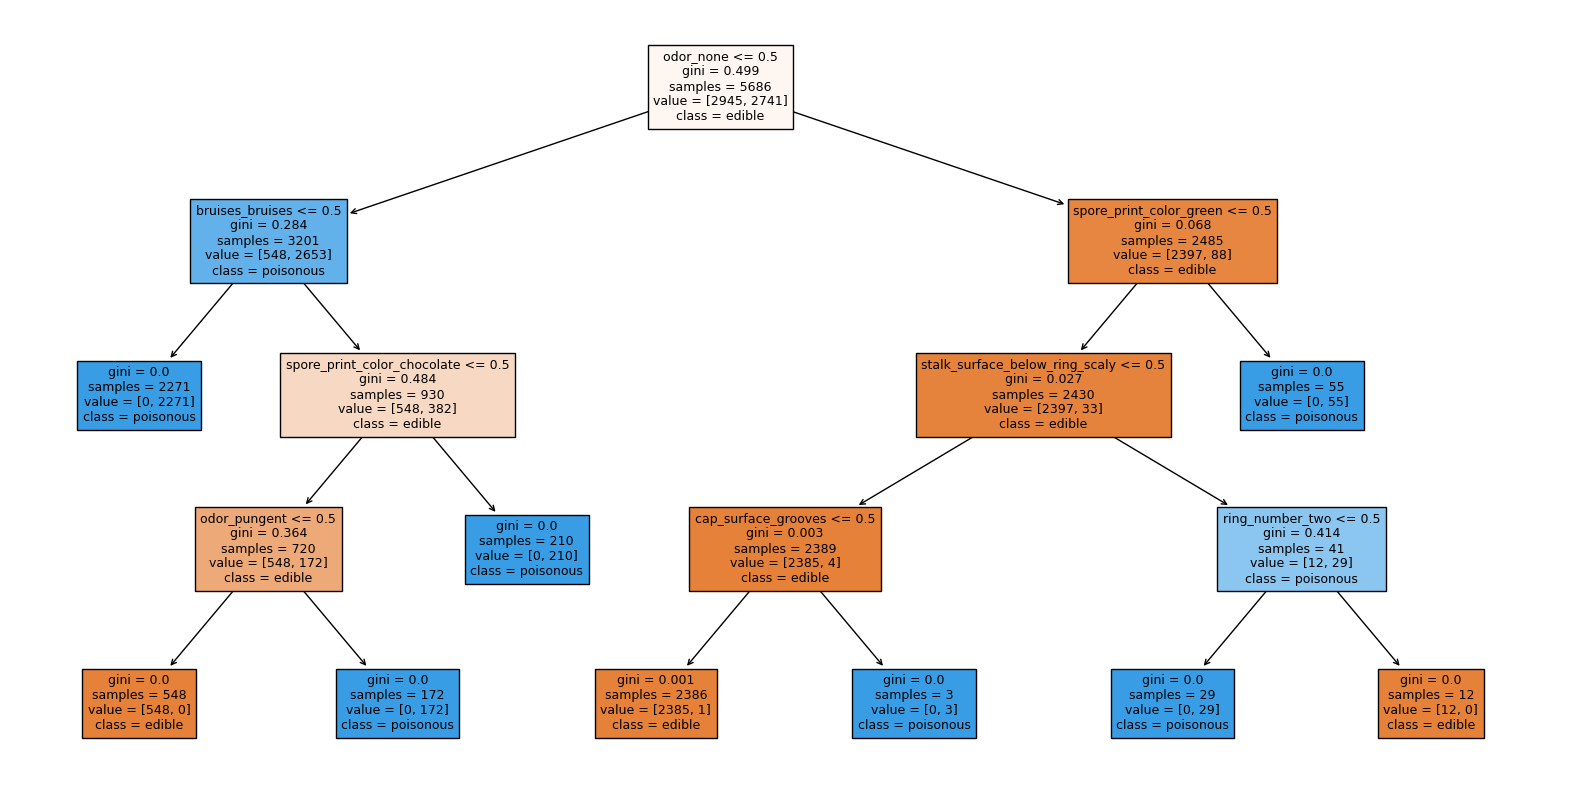

In [25]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(tree, feature_names=ohe.get_feature_names_out(),
          class_names=tree.classes_, filled=True, fontsize=9)
plt.show()

## Naive Bayes

In [ ]:
# Apply Naive Bayes Classifier

from sklearn.naive_bayes import CategoricalNB

n_categorias = [len(c) for c in ord_enc.categories_]

nb = CategoricalNB(min_categories=n_categorias)
nb.fit(X_train_ord, y_train)
y_pred_nb = nb.predict(X_test_ord)

In [28]:
# Assess the model performance by Naive Bayes Classifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

accuracy_nb = accuracy_score(y_test, y_pred_nb)
confusion_nb = confusion_matrix(y_test, y_pred_nb, labels=['edible', 'poisonous'])
classification_report_nb = classification_report(y_test, y_pred_nb, labels=['edible', 'poisonous'])

print("Accuracy:", accuracy_nb)
print("Confusion Matrix:\n", confusion_nb)
print("Classification Report:\n", classification_report_nb)


Accuracy: 0.9598031173092699
Confusion Matrix:
 [[1255    8]
 [  90 1085]]
Classification Report:
               precision    recall  f1-score   support

      edible       0.93      0.99      0.96      1263
   poisonous       0.99      0.92      0.96      1175

    accuracy                           0.96      2438
   macro avg       0.96      0.96      0.96      2438
weighted avg       0.96      0.96      0.96      2438

